# 02 · Features derivadas

| | |
|---|---|
| **Entrega** | PSet 3, sección 2 de `CD_PSet_3.pdf` (Features) |
| **Autor** | Allan Paul Gómez Ehmig (00351916) |
| **Datos** | el mismo snapshot y la misma división que `01_eda.ipynb`: solo **entrenamiento** (objetivo hasta 2023-12); el hold-out no se abre |
| **Momento de la inferencia** | el cierre del último día hábil del mes *t*: con lo que se sabe entonces se ordenan las acciones para el mes *t+1* |

### Qué pide el PDF y dónde está

| Requisito | Sección |
|---|---|
| Al menos 2 features derivadas, al menos una de un hallazgo del EDA | 1 (diseño) y 5 (decisión) |
| Qué evidencia muestra que aporta | 3 (evidencia descriptiva) y 4 (ablación con TimeSeriesSplit) |
| Por qué ya existe en el momento de la inferencia | 2 (con pruebas de disponibilidad) |
| Codificación si es categórica | 1 y 2.3 |
| Sin data leakage | 2 y 6 |

Cómo correrlo: *Restart + Run All* desde `psets/pset-03` o `notebooks/`. La ablación entrena unos 230 modelos
pequeños (1–3 min en la Mac).

In [1]:
# Carga del snapshot, preparacion (src/pipeline.py) y division temporal; el hold-out queda reservado.
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RAIZ = Path.cwd().resolve()
if RAIZ.name == 'notebooks':
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
from src.datos import cargar
from src.pipeline import (preparar, dividir, derivar, FEATURES, FEATURES_OBT, FEATURES_LINEALES, DERIVADAS,
                          MESES_OBJETIVO, REDUNDANTES, DESCARTADAS, FUGA, TARGET, preparacion, pliegues,
                          predecir_pliegues, mes_objetivo)
from src.evaluacion import errores, ic_por_mes, resumen_ic
from src.entorno import SEMILLA            # 42, la misma en todo el proyecto

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.3})
FIG = RAIZ / 'docs/figuras'; FIG.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre):
    fig.savefig(FIG / f'features_{nombre}.png', dpi=130, bbox_inches='tight')

obt, meta = cargar()
datos = preparar(obt)
train, holdout = dividir(datos)
train = train.reset_index(drop=True)
print(json.dumps({'sha256': meta['sha256'][:16], 'entrenamiento': len(train), 'holdout_reservado': len(holdout),
                  'predictores_obt': len(FEATURES_OBT), 'derivadas': len(DERIVADAS), 'features': len(FEATURES)}, indent=1))

{
 "sha256": "c356891723976bce",
 "entrenamiento": 46851,
 "holdout_reservado": 11326,
 "predictores_obt": 33,
 "derivadas": 2,
 "features": 35
}


## 1. Diseño: de los hallazgos del EDA a las features

El EDA (`docs/hallazgos_eda.csv`) dejó tres hallazgos que orientan el diseño:

- **H-EDA 2.** El mes explica el 34,5 % de la varianza del objetivo, y la dispersión entre acciones cambia mucho de
  un mes a otro (desviación entre acciones de 0,046 a 0,084 entre p10 y p90).
- **H-EDA 3.** La señal para **ordenar** acciones dentro del mes es débil: ningún predictor tiene un IC significativo.
- **H-EDA 5.** La escala de riesgo cambia 2,8 veces entre acciones.

Como la métrica técnica es el MAE (decisión W3), un error grande viene de no anticipar el **nivel y la dispersión
del mes**, que son comunes a todas las acciones. Las dos features elegidas describen el mes. Las candidatas
"por acción" se probaron y se descartaron (sección 4).

| Feature | Hallazgo | Definición | Tipo | Codificación |
|---|---|---|---|---|
| `dispersion_mes` | H-EDA 2 | desviación estándar de `ret_log_mes` entre las acciones elegibles del mes *t* | numérica, igual para todas las acciones del mes | ninguna (se escala en el Pipeline) |
| `mes_calendario_obj` (1–12) | H-EDA 2 | mes calendario del objetivo (*t+1*) | **categórica nominal**, 12 niveles | **one-hot** dentro del Pipeline (`preparacion()`), enero como referencia (11 columnas 0/1) |

Candidatas probadas y descartadas: `vol_relativa` = vol_21d / vol_63d y `momentum_por_riesgo` = momentum_12_1 /
vol_63d (H-EDA 5, eran las del PSet 2); `ret_idiosincratico_mes` = ret_log_mes − beta_252d · ret_log_sp500_mes
(H-EDA 2 aplicado a cada acción: quitar el mercado); `regimen_vol` = tercil de vol_63d dentro del mes (H-EDA 5,
categórica ordinal).

El código está en `src/pipeline.py` (`derivar`, que llama `preparar`), así que el notebook, el entrenamiento y la
inferencia usan la misma función.

In [2]:
# Candidatas descartadas: se calculan aqui solo para la ablacion (no estan en src/pipeline.py).
def candidatas(d):
    d = d.copy()
    g = d.groupby('anio_mes')
    d['vol_relativa'] = d.vol_21d / d.vol_63d.replace(0, np.nan)
    d['momentum_por_riesgo'] = d.momentum_12_1 / d.vol_63d.replace(0, np.nan)
    d['ret_idiosincratico_mes'] = d.ret_log_mes - d.beta_252d * d.ret_log_sp500_mes
    d['regimen_vol'] = g.vol_63d.transform(lambda s: pd.qcut(s.rank(method='first'), 3, labels=False)).astype(float)
    return d.replace([np.inf, -np.inf], np.nan)

train = candidatas(train)
display(train[['dispersion_mes'] + DESCARTADAS].describe().T.round(4))
display(train.groupby('mes_calendario_obj').anio_mes.nunique().rename('meses de entrenamiento por nivel').to_frame().T)

,count,mean,std,min,25%,50%,75%,max
dispersion_mes,46851.0,0.0636,0.0191,0.0337,0.0529,0.0597,0.0698,0.2216
vol_relativa,46851.0,0.9700,0.2386,0.0727,0.8049,0.9603,1.1221,1.7182
momentum_por_riesgo,46851.0,0.5066,0.9255,-3.1375,-0.1573,0.4513,1.1308,4.9235
ret_idiosincratico_mes,46851.0,-0.0019,0.0661,-0.9854,-0.0357,0.0013,0.0352,0.5158
regimen_vol,46851.0,0.9989,0.8172,0.0000,0.0000,1.0000,2.0000,2.0000


mes_calendario_obj,1,2,3,4,5,6,7,8,9,10,11,12
meses de entrenamiento por nivel,13,13,13,13,13,13,13,13,13,13,14,14


## 2. ¿Existen en el momento de la inferencia?

Una feature solo es válida si se puede calcular al cierre del mes *t* sin ver nada de *t+1*.

**2.1 `dispersion_mes`.** Usa el retorno de cada acción en el mes *t* (precio de cierre del último día hábil de *t*
contra el del mes anterior), que se conoce al cierre de *t*. Se calcula sobre **todas** las acciones elegibles del
mes, también las que dejan de cotizar en *t+1*: por eso `preparar()` deriva **antes** de quitar las filas sin
objetivo. Si se calculara después, el universo del mes dependería de quién sobrevive en *t+1*, una fuga sutil
(sesgo de supervivencia). En producción es la misma función sobre el universo elegible del mes.

**2.2 Mes calendario del objetivo.** El calendario se conoce de antemano: al cierre de diciembre se sabe que el
objetivo es enero. Es un dato determinista y no un valor observado en *t+1*.

**2.3 Codificación.** El mes es nominal: no hay un orden con sentido (diciembre no está "lejos" de enero). Se descartan:
- **ordinal 1–12**: inventa un orden y una distancia;
- **seno/coseno**: supone un patrón suave y periódico, y el que se ve en la sección 3 sube y baja de un mes a otro;
- **target encoding**: usaría medias del objetivo, se tendría que ajustar en cada pliegue y, con 13 años por nivel,
  sería muy ruidoso.

Se usa **one-hot** dentro del Pipeline (`preparacion()` en `src/pipeline.py`): `OneHotEncoder` con las 12
categorías fijas, enero como referencia (`drop='first'`, para evitar la colinealidad perfecta con el intercepto
en los modelos lineales) y `handle_unknown='error'`. Un mes desconocido falla en vez de pasar como una fila de
ceros, que sería enero. Como las categorías no se aprenden de los datos, no hay categorías nuevas en la
inferencia. Los árboles usan las mismas 11 columnas.

Las pruebas siguientes lo comprueban con los datos.

In [3]:
# Pruebas de disponibilidad: lo derivado no cambia si se altera todo lo de t+1.
alterada = obt.copy()
rng = np.random.default_rng(SEMILLA)
for c in [c for c in obt.columns if c.endswith('_siguiente')]:
    alterada[c] = rng.normal(size=len(alterada))            # objetivo y mercado de t+1 inventados
alterada.loc[alterada.sample(frac=0.2, random_state=SEMILLA).index, TARGET] = np.nan   # y otras acciones "sin t+1"
a = derivar(alterada[alterada.elegible.fillna(False).astype(bool)]).set_index(['accion_key', 'anio_mes'])
b = derivar(obt[obt.elegible.fillna(False).astype(bool)]).set_index(['accion_key', 'anio_mes'])
assert np.allclose(a[DERIVADAS].values, b.loc[a.index, DERIVADAS].values, equal_nan=True)
print('1) dispersion_mes y mes_calendario_obj no cambian al alterar el objetivo y el mercado de t+1 ni al quitar acciones sin t+1.')

# La dispersion de entrenamiento se reproduce con solo las filas del mismo mes, incluidas las que no tienen objetivo.
ok = obt[obt.elegible.fillna(False).astype(bool) & ~obt.ticker.isin(['BMS', 'AMCR'])]
manual = ok.groupby('anio_mes').ret_log_mes.std()
assert np.allclose(train.dispersion_mes, train.anio_mes.map(manual))
print('2) dispersion_mes = desviacion de ret_log_mes del mismo mes (universo elegible completo).')

assert not set(FEATURES) & set(FUGA) and not any('siguiente' in c for c in FEATURES)
print(f'3) Ninguna de las {len(FEATURES)} features esta en FUGA ni termina en _siguiente.')
Z = pd.DataFrame(preparacion().fit_transform(train[FEATURES]), columns=preparacion().fit(train[FEATURES]).get_feature_names_out())
assert list(Z.filter(like='mes_calendario').columns) == MESES_OBJETIVO and (Z[MESES_OBJETIVO].sum(axis=1) <= 1).all()
print('4) One-hot valido: a lo sumo un 1 por fila (enero = todo 0).')

1) dispersion_mes y mes_calendario_obj no cambian al alterar el objetivo y el mercado de t+1 ni al quitar acciones sin t+1.
2) dispersion_mes = desviacion de ret_log_mes del mismo mes (universo elegible completo).
3) Ninguna de las 35 features esta en FUGA ni termina en _siguiente.


4) One-hot valido: a lo sumo un 1 por fila (enero = todo 0).


## 3. Evidencia descriptiva (solo entrenamiento)

Antes de entrenar nada, conviene confirmar que cada feature mira algo que de verdad se mueve con el objetivo.

158 meses. Spearman dispersion(t) ~ dispersion del objetivo(t+1): 0.353 (p = 5.5e-06); ~ |objetivo| medio: 0.438 (p = 8.3e-09)
Media mensual del objetivo por mes calendario: ANOVA F = 1.21, p = 0.284


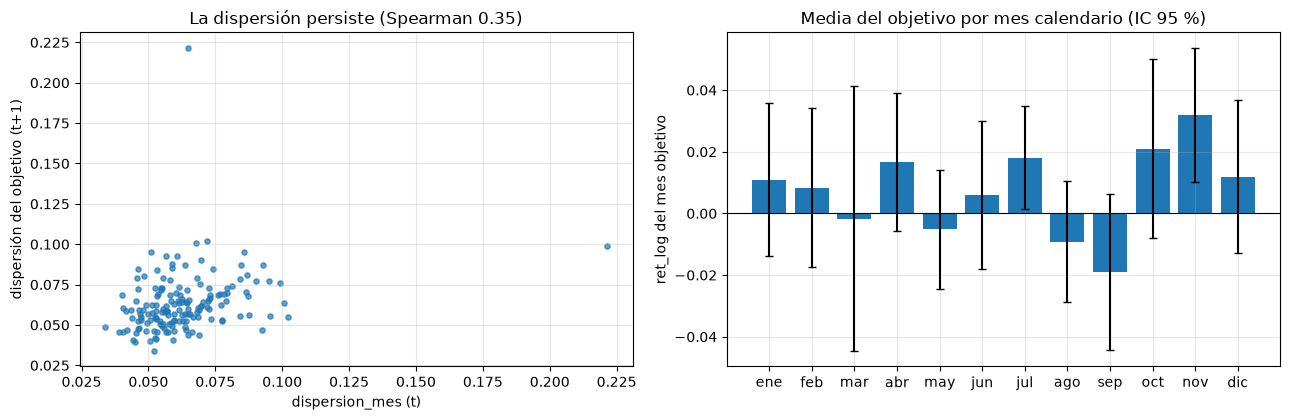

mes_obj,1,2,3,4,5,6,7,8,9,10,11,12
mean,0.0110,0.0084,-0.0018,0.0167,-0.0051,0.0060,0.0181,-0.0092,-0.0189,0.0210,0.0320,0.0120
std,0.0457,0.0476,0.0790,0.0409,0.0355,0.0444,0.0308,0.0361,0.0466,0.0534,0.0416,0.0472
size,13.0000,13.0000,13.0000,13.0000,13.0000,13.0000,13.0000,13.0000,13.0000,13.0000,14.0000,14.0000
ic95,0.0249,0.0259,0.0430,0.0222,0.0193,0.0241,0.0168,0.0196,0.0253,0.0291,0.0218,0.0247


In [4]:
# dispersion_mes(t) frente a la dispersion del objetivo (t+1) y |objetivo|; media del objetivo por mes calendario.
m = train.groupby('anio_mes').agg(dispersion_t=('dispersion_mes', 'first'), dispersion_obj=(TARGET, 'std'),
                                  abs_obj=(TARGET, lambda s: s.abs().mean()), media_obj=(TARGET, 'mean'),
                                  mes_obj=('mes_objetivo', lambda s: s.iloc[0].month))
rho_d, p_d = stats.spearmanr(m.dispersion_t, m.dispersion_obj)
rho_a, p_a = stats.spearmanr(m.dispersion_t, m.abs_obj)
print(f'{len(m)} meses. Spearman dispersion(t) ~ dispersion del objetivo(t+1): {rho_d:.3f} (p = {p_d:.1e}); '
      f'~ |objetivo| medio: {rho_a:.3f} (p = {p_a:.1e})')

cal = m.groupby('mes_obj').media_obj.agg(['mean', 'std', 'size'])
cal['ic95'] = 1.96 * cal['std'] / np.sqrt(cal['size'])
f_anova = stats.f_oneway(*[g.values for _, g in m.groupby('mes_obj').media_obj])
print(f'Media mensual del objetivo por mes calendario: ANOVA F = {f_anova.statistic:.2f}, p = {f_anova.pvalue:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].scatter(m.dispersion_t, m.dispersion_obj, s=14, alpha=0.7)
ax[0].set_xlabel('dispersion_mes (t)'); ax[0].set_ylabel('dispersión del objetivo (t+1)')
ax[0].set_title(f'La dispersión persiste (Spearman {rho_d:.2f})')
nombres = ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic']
ax[1].bar(cal.index, cal['mean'], yerr=cal['ic95'], capsize=3)
ax[1].axhline(0, color='k', lw=0.8); ax[1].set_xticks(range(1, 13), nombres)
ax[1].set_title('Media del objetivo por mes calendario (IC 95 %)'); ax[1].set_ylabel('ret_log del mes objetivo')
plt.tight_layout(); guardar(fig, 'evidencia_descriptiva'); plt.show()
display(cal.round(4).T)

In [5]:
# IC por mes (Spearman dentro del mes) de las candidatas que varian entre acciones; las de mes no ordenan acciones.
def ic_variable(c):
    ic = train.groupby('anio_mes')[[c, TARGET]].apply(
        lambda g: stats.spearmanr(g[c], g[TARGET]).statistic if g[c].nunique() > 1 else np.nan)
    return resumen_ic(ic)
tabla_ic = pd.DataFrame({c: ic_variable(c) for c in DESCARTADAS + ['ret_log_mes', 'momentum_12_1']}).T
display(tabla_ic[['ic_media', 'ic_t', 'ic_positivo_pct', 'ic_meses']].round(4))
print('dispersion_mes y mes_calendario_obj son iguales para todas las acciones del mes: su IC dentro del mes no existe. '
      'No ayudan a ordenar; ayudan a anticipar el nivel y la escala del mes, que es lo que mide el MAE.')

,ic_media,ic_t,ic_positivo_pct,ic_meses
vol_relativa,0.0034,0.3918,0.4747,158.0
momentum_por_riesgo,0.0001,0.0029,0.5063,158.0
ret_idiosincratico_mes,-0.0214,-1.5527,0.4367,158.0
regimen_vol,0.0018,0.0876,0.4747,158.0
ret_log_mes,-0.0205,-1.3712,0.4620,158.0
momentum_12_1,-0.0048,-0.2649,0.5063,158.0


dispersion_mes y mes_calendario_obj son iguales para todas las acciones del mes: su IC dentro del mes no existe. No ayudan a ordenar; ayudan a anticipar el nivel y la escala del mes, que es lo que mide el MAE.


**Lectura.**
- **La dispersión de un mes anticipa la del siguiente**, y también el tamaño medio del retorno |objetivo|
  (Spearman ≈ 0,35 y 0,44, p < 1e-5): el riesgo transversal persiste. Es evidencia directa de que
  `dispersion_mes` informa sobre la escala del error que mide el MAE.
- **El mes calendario no muestra diferencias de nivel significativas por sí solo** (ANOVA p ≈ 0,28). Con 13 años
  por mes, cada intervalo es ancho. La evidencia descriptiva es débil y la decide la ablación.
- **Las candidatas por acción tienen un IC medio cercano a 0** (H-EDA 3).

La prueba decisiva es la siguiente: ¿bajan el MAE **fuera de muestra**?

## 4. Ablación con validación temporal (TimeSeriesSplit)

Se usan los pliegues oficiales, `pliegues()` de `src/pipeline.py`: `TimeSeriesSplit` sobre los meses, 7
pliegues de 12 meses (cada año 2017–2023, 84 meses fuera de muestra), ventana expansiva y un mes de separación
(sección 3 del PDF, `03_preparacion_validacion.ipynb`). Cada modelo pasa por `crear_pipeline()`, así que la
imputación, el escalado y el one-hot se ajustan solo con el entrenamiento de cada pliegue. Cada configuración agrega features a la **base** (los 33 predictores de la OBT) y se compara
con ella.

- **Modelos.** Ridge (imputar mediana, escalar, α = 10) y LightGBM pequeño con pérdida L1 (la del MAE). El
  LightGBM se repite con 3 semillas (42, 43 y 44: la del proyecto y las dos siguientes) para separar la señal
  del ruido del muestreo.
- **Prueba.** *t* pareado sobre la diferencia de MAE mensual (configuración − base) en los 84 meses: negativo
  significa que la feature ayuda.

In [6]:
# Ablacion: base (33 de la OBT) + cada derivada / candidata, Ridge y LightGBM (3 semillas), pliegues TimeSeriesSplit.
from sklearn.linear_model import Ridge
from lightgbm import LGBMRegressor

regimen = pd.get_dummies(train.regimen_vol.astype('Int64'), prefix='regimen_vol', drop_first=True).astype(float)
train = train.join(regimen)
BASE_ABL = list(FEATURES_OBT)
CONFIG = {'base (33 OBT)': [],
          '+ dispersion_mes': ['dispersion_mes'],
          '+ mes calendario (one-hot)': ['mes_calendario_obj'],
          '+ ambas (FEATURES)': DERIVADAS,
          '+ vol_relativa': ['vol_relativa'],
          '+ momentum_por_riesgo': ['momentum_por_riesgo'],
          '+ ret_idiosincratico_mes': ['ret_idiosincratico_mes'],
          '+ regimen_vol (one-hot)': list(regimen.columns)}
def ridge(_):
    return Ridge(alpha=10.0)
def lgbm(semilla):
    return LGBMRegressor(n_estimators=200, learning_rate=0.03, num_leaves=15, min_child_samples=200, subsample=0.8,
                         subsample_freq=1, colsample_bytree=0.8, objective='l1', random_state=semilla, verbose=-1)
MODELOS = {'ridge': (ridge, [SEMILLA]), 'lightgbm': (lgbm, [SEMILLA, SEMILLA + 1, SEMILLA + 2])}   # 42, 43, 44
cv = pliegues(train)
mo = mes_objetivo(train)
ventana_de = {}
for it, iv in cv:
    ventana_de.update({m: f'val_{mo[iv].min().year}' for m in train.anio_mes.iloc[iv].unique()})

predicciones = {}
for nombre_m, (fabrica, semillas) in MODELOS.items():
    for nombre_c, extra in CONFIG.items():
        for s in semillas:     # crear_pipeline: mediana + escalar (numericas) y moda + one-hot (mes), por pliegue
            predicciones[(nombre_m, nombre_c, s)] = predecir_pliegues(fabrica(s), train, features=BASE_ABL + extra, cv=cv)
print(f'{len(predicciones)} corridas x {len(cv)} ventanas; {train.anio_mes.iloc[np.concatenate([iv for _, iv in cv])].nunique()} meses fuera de muestra')

32 corridas x 7 ventanas; 84 meses fuera de muestra


,modelo,configuracion,mae,delta_mae,t_pareado,ventanas_que_mejoran,ic_medio
0,ridge,base (33 OBT),0.06966,+0.00000,+nan,0/7,-0.0378
1,ridge,+ dispersion_mes,0.06839,-0.00127,-1.57,6/7,-0.0339
2,ridge,+ mes calendario (one-hot),0.06976,+0.00012,+0.17,3/7,-0.0349
3,ridge,+ ambas (FEATURES),0.06823,-0.00139,-1.26,5/7,-0.0312
4,ridge,+ vol_relativa,0.06967,+0.00001,+0.20,3/7,-0.0364
5,ridge,+ momentum_por_riesgo,0.06969,+0.00002,+0.15,3/7,-0.0264
6,ridge,+ ret_idiosincratico_mes,0.06967,+0.00000,+0.31,2/7,-0.0402
7,ridge,+ regimen_vol (one-hot),0.06968,+0.00002,+0.07,5/7,-0.0314
8,lightgbm,base (33 OBT),0.06678,+0.00000,+nan,0/7,-0.0014
9,lightgbm,+ dispersion_mes,0.06601,-0.00077,-0.69,5/7,+0.0227


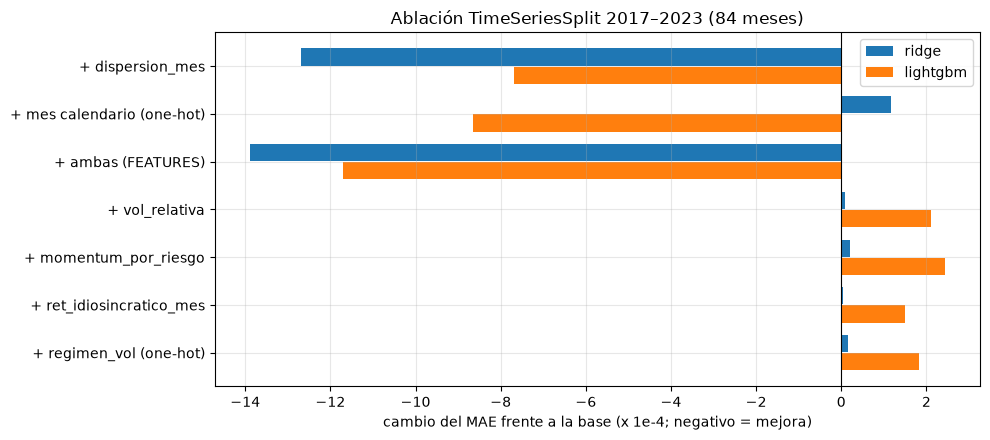

In [7]:
# Resumen de la ablacion: MAE, diferencia con la base, t pareado por mes, IC y ventanas en las que mejora.
def mae_mensual(o):
    return (o.pred - o.real).abs().groupby(o.anio_mes).mean()
filas = []
for nombre_m, (_, semillas) in MODELOS.items():
    for nombre_c in CONFIG:
        dif, maes, ics = [], [], []
        for s in semillas:
            o, b = predicciones[(nombre_m, nombre_c, s)], predicciones[(nombre_m, 'base (33 OBT)', s)]
            dif.append(mae_mensual(o) - mae_mensual(b)); maes.append(errores(o)['mae']); ics.append(resumen_ic(ic_por_mes(o))['ic_media'])
        dd = pd.concat(dif, axis=1).mean(axis=1)            # promedio de semillas, por mes
        por_ventana = dd.groupby(dd.index.map(ventana_de)).mean()
        t = dd.mean() / (dd.std(ddof=1) / np.sqrt(len(dd))) if dd.std() > 0 else np.nan
        filas.append({'modelo': nombre_m, 'configuracion': nombre_c, 'mae': np.mean(maes), 'delta_mae': dd.mean(),
                      't_pareado': t, 'ventanas_que_mejoran': f'{int((por_ventana < 0).sum())}/{len(por_ventana)}',
                      'ic_medio': np.mean(ics)})
ablacion = pd.DataFrame(filas)
ablacion.to_csv(RAIZ / 'docs/ablacion_features.csv', index=False)
display(ablacion.style.format({'mae': '{:.5f}', 'delta_mae': '{:+.5f}', 't_pareado': '{:+.2f}', 'ic_medio': '{:+.4f}'})
        .background_gradient(subset=['t_pareado'], cmap='RdYlGn_r', vmin=-3, vmax=3))

fig, ax = plt.subplots(figsize=(10, 4.5))
otras = ablacion[ablacion.configuracion != 'base (33 OBT)']
for k, (nombre_m, g) in enumerate(otras.groupby('modelo', sort=False)):
    pos = np.arange(len(g)) + (k - 0.5) * 0.38
    ax.barh(pos, g.delta_mae * 1e4, height=0.36, label=nombre_m)
ax.set_yticks(np.arange(len(g)), g.configuracion); ax.axvline(0, color='k', lw=0.8); ax.invert_yaxis()
ax.set_xlabel('cambio del MAE frente a la base (x 1e-4; negativo = mejora)'); ax.legend()
ax.set_title('Ablación TimeSeriesSplit 2017–2023 (84 meses)'); plt.tight_layout(); guardar(fig, 'ablacion'); plt.show()

In [8]:
# Lectura automatica de la ablacion (se reescribe si cambian los datos).
def fila(m, c):
    return ablacion[(ablacion.modelo == m) & (ablacion.configuracion == c)].iloc[0]
for c in ['+ dispersion_mes', '+ mes calendario (one-hot)', '+ ambas (FEATURES)']:
    r, l = fila('ridge', c), fila('lightgbm', c)
    print(f"{c:28s} Ridge dMAE {r.delta_mae:+.5f} (t {r.t_pareado:+.2f}, mejora {r.ventanas_que_mejoran}) | "
          f"LightGBM dMAE {l.delta_mae:+.5f} (t {l.t_pareado:+.2f}, mejora {l.ventanas_que_mejoran}); "
          f"IC LightGBM {fila('lightgbm', 'base (33 OBT)').ic_medio:+.4f} -> {l.ic_medio:+.4f}")
peores = ablacion[(ablacion.configuracion.isin(['+ vol_relativa', '+ momentum_por_riesgo', '+ ret_idiosincratico_mes',
                                                '+ regimen_vol (one-hot)']))]
print('Descartadas, t pareado (Ridge / LightGBM):',
      {c: f"{g.set_index('modelo').t_pareado['ridge']:+.2f} / {g.set_index('modelo').t_pareado['lightgbm']:+.2f}"
       for c, g in peores.groupby('configuracion')})

+ dispersion_mes             Ridge dMAE -0.00127 (t -1.57, mejora 6/7) | LightGBM dMAE -0.00077 (t -0.69, mejora 5/7); IC LightGBM -0.0014 -> +0.0227
+ mes calendario (one-hot)   Ridge dMAE +0.00012 (t +0.17, mejora 3/7) | LightGBM dMAE -0.00086 (t -2.04, mejora 4/7); IC LightGBM -0.0014 -> -0.0087
+ ambas (FEATURES)           Ridge dMAE -0.00139 (t -1.26, mejora 5/7) | LightGBM dMAE -0.00117 (t -1.04, mejora 7/7); IC LightGBM -0.0014 -> +0.0253
Descartadas, t pareado (Ridge / LightGBM): {'+ momentum_por_riesgo': '+0.15 / +1.48', '+ regimen_vol (one-hot)': '+0.07 / +1.46', '+ ret_idiosincratico_mes': '+0.31 / +0.96', '+ vol_relativa': '+0.20 / +1.34'}


## 5. Decisión y evidencia por feature

Las cifras son las de la sección 4 (`docs/ablacion_features.csv`).

| Feature | Evidencia de que aporta | ¿Existe en la inferencia? | Codificación |
|---|---|---|---|
| `dispersion_mes` | **Descriptiva:** la dispersión persiste y anticipa \|objetivo\| (Spearman 0,35 y 0,44, p < 1e-5). **Ablación:** baja el MAE en los dos modelos (Ridge −0,0013, mejora en 6 de 7 años; LightGBM −0,0008, 5 de 7). En LightGBM el IC pasa de −0,001 a +0,023. **Límite:** por sí sola no llega a \|t\| ≥ 2. Se queda por ser consistente en dirección, modelos y años | Sí: solo retornos del mes *t* del universo elegible de *t*, calculada antes de filtrar por objetivo (pruebas 1 y 2) | numérica; el rango transversal no la toca (`DE_MERCADO`) |
| Mes calendario del objetivo | **Descriptiva débil:** ANOVA p ≈ 0,28. **Ablación:** en LightGBM baja el MAE −0,0009 con t ≈ −2,0 sobre 84 meses, la única con \|t\| ≥ 2 (mejora en 4 de 7 años); en Ridge no ayuda. El árbol la usa en interacción con otras variables, no como un nivel fijo por mes | Sí: el calendario se conoce de antemano (prueba 1) | one-hot, 11 columnas, enero como referencia, categorías fijas |
| `vol_relativa`, `momentum_por_riesgo` (PSet 2) | No bajan el MAE en ningún modelo: en Ridge el cambio es ≈ 0 y en LightGBM lo suben un poco (+0,0002, t ≈ +1,3 a +1,5) | Sí, pero se descartan | — |
| `ret_idiosincratico_mes` | IC algo más negativo que `ret_log_mes` (reversión de corto plazo), no baja el MAE | Sí, pero se descarta | — |
| `regimen_vol` | No baja el MAE; en LightGBM lo sube (t ≈ +1,5) | Sí, pero se descarta | habría sido ordinal (0/1/2), o one-hot como se probó |

**Juntas.** Las dos juntas dan la mayor baja del MAE en los dos modelos (Ridge −0,0014, mejora en 5 de 7 años;
LightGBM −0,0012, mejora en los 7), aunque sin \|t\| ≥ 2. Las dos quedan en `FEATURES`; el filtro `SelectKBest`
del Pipeline y el tuning deciden por modelo, y la ablación final se reporta con y sin ellas.

**Sensibilidad a la semilla.** Al pasar las semillas de LightGBM de (1, 2, 3) a (42, 43, 44), la del proyecto,
cambian las magnitudes (por ejemplo, el *t* del mes calendario pasó de −2,3 a −2,0), pero no las conclusiones: las
dos elegidas bajan el MAE y las descartadas no. Con una señal tan débil, una diferencia de 0,0001 en el MAE está
dentro del ruido del muestreo de los árboles.

**Riesgo del mes calendario.** El efecto puede ser un patrón del periodo y no estacionalidad estable. La ablación
es fuera de muestra (cada año se valida con un modelo entrenado solo con los años previos) y la columna
`ventanas_que_mejoran` muestra en cuántos de los 7 años ayuda. En el hold-out (2024–2026) se reporta con y sin ella.

**Lo que cambió en el código.**
- `src/pipeline.py`: `DERIVADAS = ['dispersion_mes', 'mes_calendario_obj']`, `NUMERICAS` = 33 + 1,
  `CATEGORICAS = ['mes_calendario_obj']`, `FEATURES` = 35 columnas de X (45 tras el one-hot de `preparacion()`).
  `DESCARTADAS` documenta las candidatas.
- `FEATURES_LINEALES` quita las 4 columnas `REDUNDANTES` (las combinaciones lineales exactas del EDA, sección 6b)
  para los modelos lineales sin regularizar (sección 6).
- `src/modelos/tabulares.py`: las derivadas de mes entran en `DE_MERCADO`, así que `RangoTransversal` no las
  convierte en percentiles. Serían todas 0,5 porque son iguales dentro del mes.

## 6. Redundancia y auditoría de fuga

In [9]:
# Rango de la matriz de features: completo para FEATURES_LINEALES (sin las 4 combinaciones exactas del EDA).
from src.pipeline import separar
def rango(cols):
    Z = preparacion(*separar(cols)).fit_transform(train[cols])     # tras imputar, escalar y one-hot
    return Z.shape[1], np.linalg.matrix_rank(Z)
print('FEATURES: {} columnas tras preparar, rango {}'.format(*rango(FEATURES)))
print('FEATURES_LINEALES (sin {}): {} columnas tras preparar, rango {}'.format(REDUNDANTES, *rango(FEATURES_LINEALES)))

# Auditoria: nada del futuro en X y pliegues sin fuga (verificar_sin_fuga se llama en cada ventana).
assert not set(FEATURES) & set(FUGA)
for it, iv in cv:
    assert mo[it].max() < mo[iv].min() - 1                    # gap de 1 mes
    assert mo[iv].max() <= pd.Period('2023-12', freq='M')
print(f'{len(cv)} pliegues TimeSeriesSplit: el ultimo objetivo de entrenamiento queda al menos 2 meses antes del primero de '
      'validacion (embargo) y ninguna toca el hold-out.')

FEATURES: 45 columnas tras preparar, rango 41


FEATURES_LINEALES (sin ['exceso_sp500_log_mes', 'nocturno_log_mes', 'nocturno_prom_21d', 'ret_log_252d']): 41 columnas tras preparar, rango 41
7 pliegues TimeSeriesSplit: el ultimo objetivo de entrenamiento queda al menos 2 meses antes del primero de validacion (embargo) y ninguna toca el hold-out.


**Fuentes de fuga revisadas.**
- **Columnas del futuro.** Las de `FUGA` (objetivo, mercado de *t+1*, `sigue_en_sp500`, bolsa actual, última
  cotización) nunca entran como predictores (prueba 3).
- **Universo del mes.** `dispersion_mes` se calcula antes de quitar las filas sin objetivo, así que no hay sesgo de
  supervivencia (2.1).
- **Imputación.** La mediana se ajusta dentro del Pipeline en cada ventana. La interpolación de huecos (EDA,
  sección 2) se hace a cada lado del corte. Dentro del entrenamiento podría usar un mes posterior, pero hoy hay
  0 huecos.
- **Precios ajustados.** Yahoo ajusta toda la historia por dividendos y *splits* posteriores: los niveles de precio no
  son *point-in-time*. Los predictores usan retornos y cocientes, que el ajuste no cambia salvo el día del evento.
  Silver rellena hacia adelante (nunca con un vecino posterior) y en esta corrida hubo 0 días imputados.